## Part A

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, 
    classification_report, confusion_matrix, roc_curve, auc
)

# 1. Download and Load Dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"

# Column names based on UCI repository documentation
feature_names = [
    "erythema", "scaling", "definite_borders", "itching", "koebner_phenomenon",
    "polygonal_papules", "follicular_papules", "oral_mucosal_involvement",
    "knee_and_elbow_involvement", "scalp_involvement", "family_history",
    "melanin_incontinence", "eosinophils_in_infiltrate", "pnl_infiltrate",
    "fibrosis_of_papillary_dermis", "exocytosis", "acanthosis", "hyperkeratosis",
    "parakeratosis", "elongation_of_rete_ridges", "thinning_of_suprapapillary_epidermis",
    "spongiform_pustule", "munro_microabcess", "focal_hypergranulosis",
    "disappearance_of_granular_layer", "vacuolization_and_damage", "spongiosis",
    "saw_tooth_appearance_of_retes", "follicular_horn_plug", "perivascular_infiltrate",
    "band_like_infiltrate", "age"
]
# Additional clinical feature before target
feature_names.insert(10, "inflammatory_monolayer") # 33 features total
column_names = feature_names + ["class"]

df = pd.read_csv(url, header=None, names=column_names, na_values="?")

print("Dataset Shape:", df.shape)
print("\n--- Feature Data Types ---")
print(df.dtypes.value_counts())

print("\n--- Summary Statistics ---")
print(df.describe().T[["mean", "std", "min", "50%", "max"]])

Dataset Shape: (366, 34)

--- Feature Data Types ---
int64      33
float64     1
Name: count, dtype: int64

--- Summary Statistics ---
                                           mean        std  min   50%   max
erythema                               1.795082   0.701527  0.0   2.0   3.0
scaling                                1.549180   0.907525  0.0   2.0   3.0
definite_borders                       1.366120   1.138299  0.0   1.0   3.0
itching                                0.633880   0.908016  0.0   0.0   3.0
koebner_phenomenon                     0.448087   0.957327  0.0   0.0   3.0
polygonal_papules                      0.166667   0.570588  0.0   0.0   3.0
follicular_papules                     0.377049   0.834147  0.0   0.0   3.0
oral_mucosal_involvement               0.614754   0.982979  0.0   0.0   3.0
knee_and_elbow_involvement             0.519126   0.905639  0.0   0.0   3.0
scalp_involvement                      0.125683   0.331946  0.0   0.0   1.0
inflammatory_monolayer       

In [2]:
# Check missing values
missing_counts = df.isnull().sum()
print("\n--- Missing Values per Column ---")
print(missing_counts[missing_counts > 0])

# Check duplicates
duplicate_rows = df.duplicated().sum()
print(f"\nDuplicate Rows Found: {duplicate_rows}")
if duplicate_rows > 0:
    df.drop_duplicates(inplace=True)

# Impute missing values in 'age' using Median Imputation
imputer = SimpleImputer(strategy="median")
df["age"] = imputer.fit_transform(df[["age"]])

# Outlier Detection via Interquartile Range (IQR) on continuous feature 'age'
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df["age"] < lower_bound) | (df["age"] > upper_bound)]
print(f"Age Outliers Count: {len(outliers)}")


--- Missing Values per Column ---
age    8
dtype: int64

Duplicate Rows Found: 0
Age Outliers Count: 0


C:\Users\hpCND\AppData\Local\Temp\ipykernel_3280\2392162343.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y="disease_name", data=df_plot, palette="viridis", ax=axes[0, 0])
C:\Users\hpCND\AppData\Local\Temp\ipykernel_3280\2392162343.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="class", y="age", data=df, palette="Set2", ax=axes[1, 0])


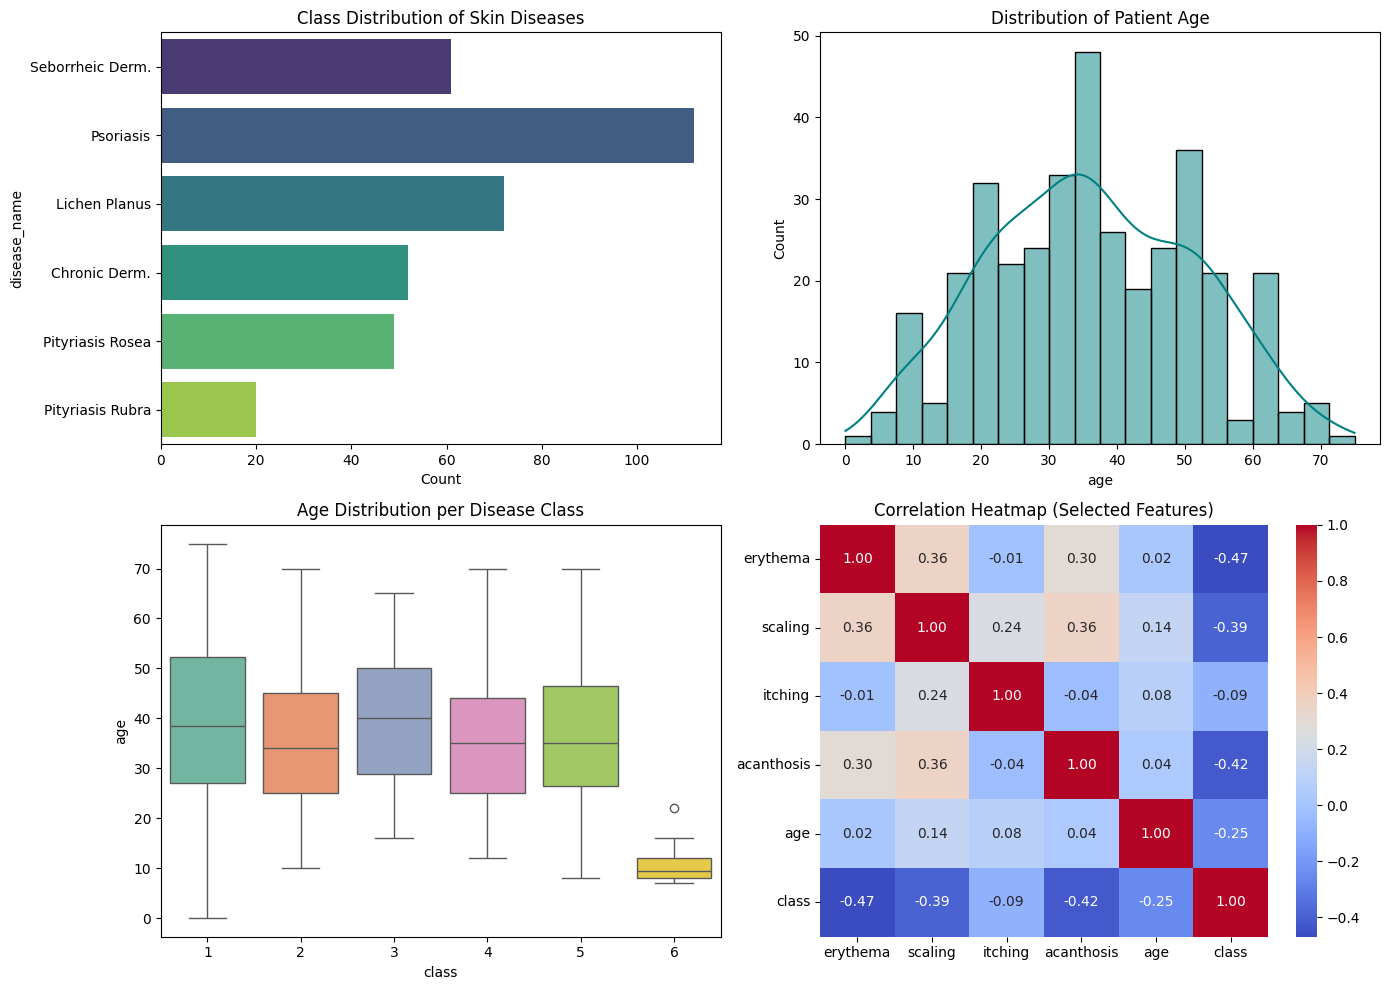

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Visual 1: Class Distribution
disease_map = {
    1: "Psoriasis", 2: "Seborrheic Derm.", 3: "Lichen Planus",
    4: "Pityriasis Rosea", 5: "Chronic Derm.", 6: "Pityriasis Rubra"
}
df_plot = df.copy()
df_plot["disease_name"] = df_plot["class"].map(disease_map)

sns.countplot(y="disease_name", data=df_plot, palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Class Distribution of Skin Diseases")
axes[0, 0].set_xlabel("Count")

# Visual 2: Age Histogram across Classes
sns.histplot(data=df, x="age", kde=True, bins=20, color="teal", ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Patient Age")

# Visual 3: Age Boxplot by Class
sns.boxplot(x="class", y="age", data=df, palette="Set2", ax=axes[1, 0])
axes[1, 0].set_title("Age Distribution per Disease Class")

# Visual 4: Correlation Heatmap for key clinical features
sample_features = ["erythema", "scaling", "itching", "acanthosis", "age", "class"]
sns.heatmap(df[sample_features].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap (Selected Features)")

plt.tight_layout()
plt.show()

## Part B

In [4]:
# Separate Features (X) and Target (y)
X = df.drop(columns=["class"])
y = df["class"]

# 1. Encode Target Variable (0-indexed for Scikit-Learn compatibility)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 2. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_encoded
)

# 3. Standardize Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set size: {X_train_scaled.shape}")
print(f"Testing set size: {X_test_scaled.shape}")

Training set size: (292, 33)
Testing set size: (74, 33)


## Part C

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# Train all models
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

NameError: name 'X_train_scaled' is not defined

In [6]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-Score": f1
    })

comparison_df = pd.DataFrame(results)
print("--- Model Performance Comparison ---")
print(comparison_df.to_string(index=False))

--- Model Performance Comparison ---
                 Model  Accuracy  Macro Precision  Macro Recall  Macro F1-Score
   Logistic Regression  0.959459         0.961538      0.961111        0.957362
   K-Nearest Neighbors  0.891892         0.896296      0.895531        0.888327
Support Vector Machine  0.972973         0.972222      0.972222        0.969697
         Random Forest  0.959459         0.954545      0.955556        0.954451


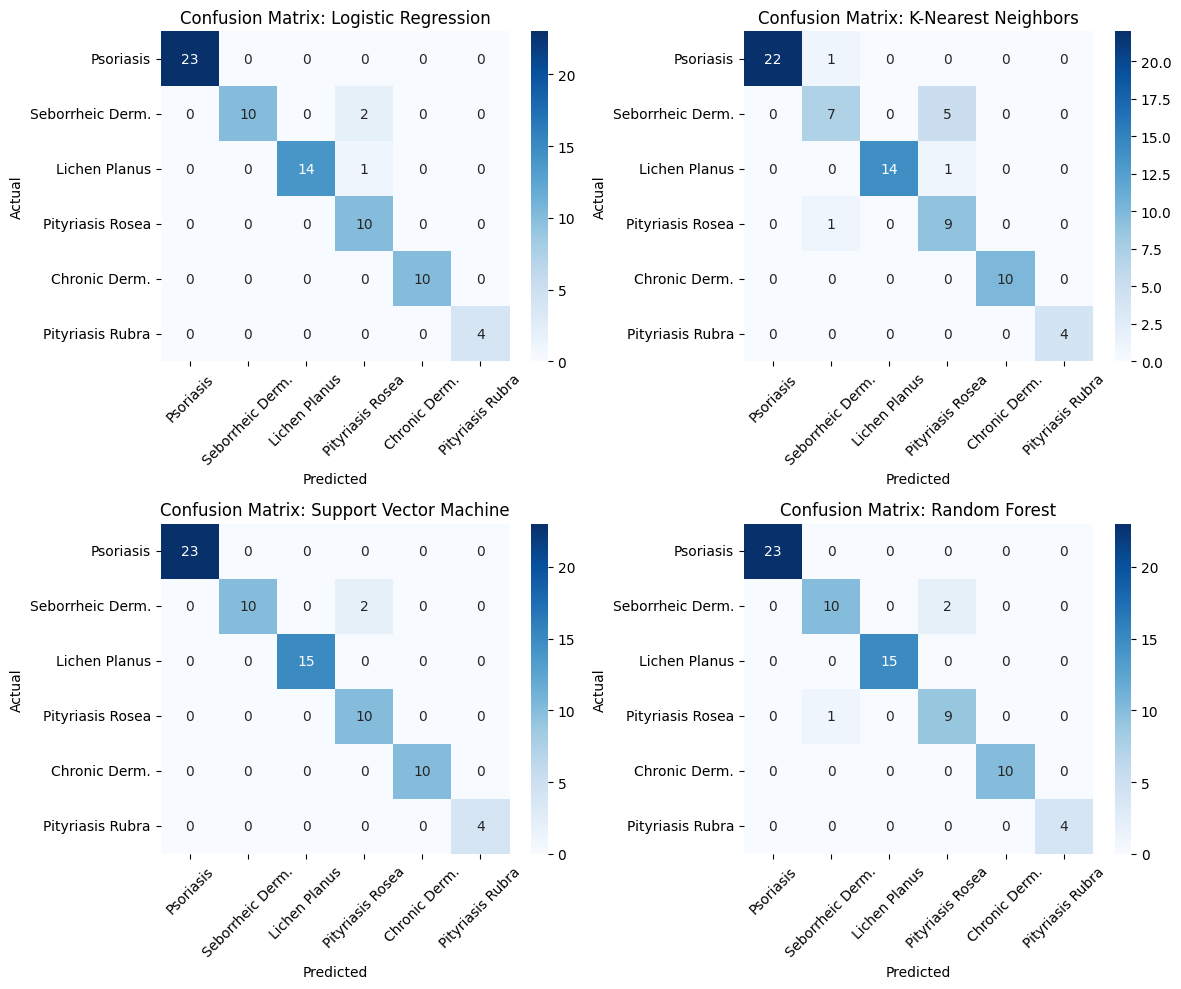

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

class_labels = [disease_map[i+1] for i in range(6)]

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=class_labels, yticklabels=class_labels, ax=axes[idx])
    axes[idx].set_title(f"Confusion Matrix: {name}")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")
    axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

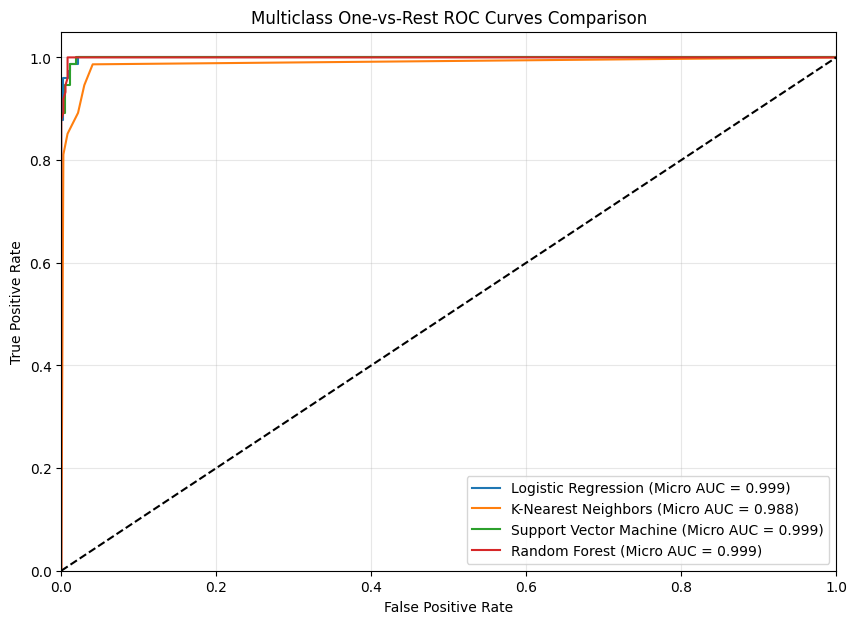

In [8]:
# Binarize target labels for One-vs-Rest ROC curve
y_test_bin = label_binarize(y_test, classes=list(range(6)))
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(10, 7))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_scaled)
    else:
        y_score = model.decision_function(X_test_scaled)
        
    # Compute micro-average ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, label=f"{name} (Micro AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", lw=1.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass One-vs-Rest ROC Curves Comparison")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()